In [ ]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

In [ ]:
df = pd.read_csv('/content/Iris.csv')
df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


In [ ]:
le = {}
df_enc = df.copy()
for col in df_enc.columns:
    le[col] = LabelEncoder()
    df_enc[col] = le[col].fit_transform(df_enc[col])
df_en

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,0,8,14,4,1,0
1,1,6,9,4,1,0
2,2,4,11,3,1,0
3,3,3,10,5,1,0
4,4,7,15,4,1,0
...,...,...,...,...,...,...
145,145,24,9,28,19,2
146,146,20,4,26,15,2
147,147,22,9,28,16,2
148,148,19,13,30,19,2


In [ ]:
x = df_enc[['Id','SepalLengthCm','SepalWidthCm','PetalLengthCm','PetalWidthCm']]
y = df_enc['Species']
x

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
0,0,8,14,4,1
1,1,6,9,4,1
2,2,4,11,3,1
3,3,3,10,5,1
4,4,7,15,4,1
...,...,...,...,...,...
145,145,24,9,28,19
146,146,20,4,26,15
147,147,22,9,28,16
148,148,19,13,30,19


In [ ]:
y

,Species
0,0
1,0
2,0
3,0
4,0
...,...
145,2
146,2
147,2
148,2


In [ ]:
model = CategoricalNB()
model.fit(x,y)

CategoricalNB()

In [ ]:
test =[[0,1,5.1,3.5,1.4]]

In [ ]:
test

[[0, 1, 5.1, 3.5, 1.4]]

In [ ]:
print("\n---- Prediction ----------------------------------")
for t in test:
  # Your features are: ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']
  # We wrap t in a list because model.predict expects a 2D array-like structure
  row = [t]

  # Predict class numerical label and inverse transform using 'Species' encoder
  pred_encoded = model.predict(row)[0]
  pre = le['Species'].inverse_transform([pred_encoded])[0]
  prob = model.predict_proba(row)[0]

  print(f"Input : Id={t[0]} SepalLength={t[1]} SepalWidth={t[2]} PetalLength={t[3]} PetalWidth={t[4]}")
  print(f"Output: Species={pre}")
  print(f"Result : Species -> {pre}")
  print(f"P(Setosa) = {prob[0]:.4f}, P(Versicolor) = {prob[1]:.4f}, P(Virginica) = {prob[2]:.4f}")
  print("--------------------------------------------------")


---- Prediction ----------------------------------
Input : Id=0 SepalLength=1 SepalWidth=5.1 PetalLength=3.5 PetalWidth=1.4
Output: Species=Iris-setosa
Result : Species -> Iris-setosa
P(Setosa) = 0.9962, P(Versicolor) = 0.0021, P(Virginica) = 0.0016
--------------------------------------------------


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


In [ ]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(x)
print(f"\n Training Accuracy: {accuracy_score(y,y_pred)*100:.2f}%")


 Training Accuracy: 97.33%


/tmp/ipykernel_1424/387707237.py:47: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Species', y='SepalLengthCm', ax=axes[1, 0], palette='Set2')
/tmp/ipykernel_1424/387707237.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Species', y='PetalLengthCm', ax=axes[1, 1], palette='Set2')


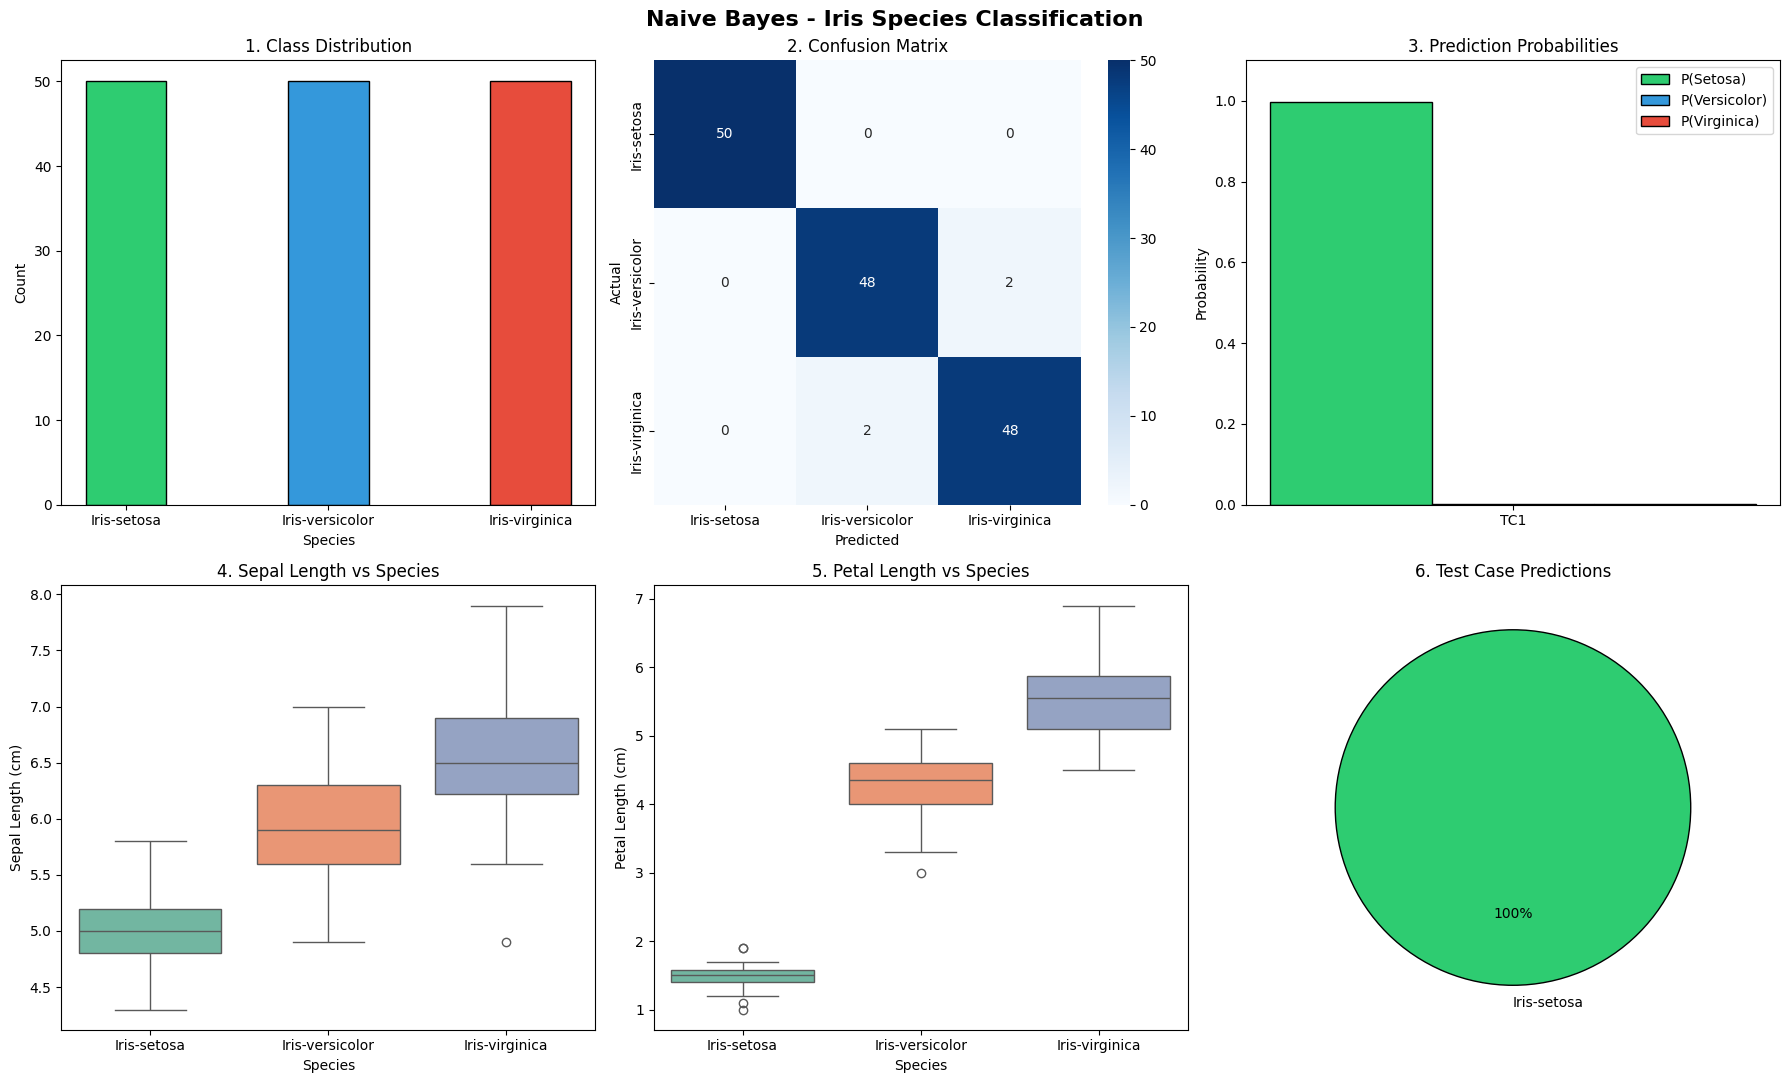

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Configure subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("Naive Bayes - Iris Species Classification", fontsize=16, fontweight='bold')

# 1. Class Distribution
counts = df['Species'].value_counts()
axes[0, 0].bar(counts.index, counts.values, color=['#2ecc71', '#3498db', '#e74c3c'], edgecolor='black', width=0.4)
axes[0, 0].set_title("1. Class Distribution")
axes[0, 0].set_xlabel("Species")
axes[0, 0].set_ylabel("Count")

# 2. Confusion Matrix
cm = confusion_matrix(y, model.predict(x))
class_names = le['Species'].classes_
sns.heatmap(cm, annot=True, cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=axes[0, 1], fmt='d')
axes[0, 1].set_title("2. Confusion Matrix")
axes[0, 1].set_xlabel("Predicted")
axes[0, 1].set_ylabel("Actual")

# Define test cases for visualization using the last predicted prob
test_cases = ["TC1"]
probs_setosa = [prob[0]]
probs_versicolor = [prob[1]]
probs_virginica = [prob[2]]

# 3. Prediction Probabilities
tc_labels = [f"TC{i+1}" for i in range(len(test_cases))]
x_axis = np.arange(len(tc_labels))
w = 0.2
axes[0, 2].bar(x_axis - w, probs_setosa, w, label='P(Setosa)', color='#2ecc71', edgecolor='black')
axes[0, 2].bar(x_axis, probs_versicolor, w, label='P(Versicolor)', color='#3498db', edgecolor='black')
axes[0, 2].bar(x_axis + w, probs_virginica, w, label='P(Virginica)', color='#e74c3c', edgecolor='black')
axes[0, 2].set_title("3. Prediction Probabilities")
axes[0, 2].set_ylim(0, 1.1)
axes[0, 2].set_ylabel("Probability")
axes[0, 2].set_xticks(x_axis)
axes[0, 2].set_xticklabels(tc_labels)
axes[0, 2].legend()

# 4. Sepal Length Distribution vs Species
sns.boxplot(data=df, x='Species', y='SepalLengthCm', ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title("4. Sepal Length vs Species")
axes[1, 0].set_xlabel("Species")
axes[1, 0].set_ylabel("Sepal Length (cm)")

# 5. Petal Length Distribution vs Species
sns.boxplot(data=df, x='Species', y='PetalLengthCm', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title("5. Petal Length vs Species")
axes[1, 1].set_xlabel("Species")
axes[1, 1].set_ylabel("Petal Length (cm)")

# 6. Test Case Predictions
predictions = [pre]
pred_series = pd.Series(predictions)
pred_counts = pred_series.value_counts()
color_map = {'Iris-setosa': '#2ecc71', 'Iris-versicolor': '#3498db', 'Iris-virginica': '#e74c3c'}
colors_pie = [color_map.get(l, '#95a5a6') for l in pred_counts.index]
axes[1, 2].pie(pred_counts.values, labels=pred_counts.index, colors=colors_pie, autopct='%1.0f%%', startangle=90, wedgeprops={'edgecolor': 'black'})
axes[1, 2].set_title("6. Test Case Predictions")

plt.tight_layout()
plt.show()